# 02 Trend and seasonality (BQ1, BQ2): R version

**BQ1:** How have revenue, orders and active customers changed over the two years?
**BQ2:** What repeats by month, weekday and hour?

Same questions and data as `02_trend_seasonality_py.ipynb`; the results must agree.
Input: `data/processed/` from `src/clean_data.py`. Revenue = net product revenue
(gross product sales − product cancellations), per docs/02.

## Setup and data

In [1]:
suppressPackageStartupMessages({
  library(arrow); library(dplyr); library(tidyr); library(ggplot2)
  library(lubridate); library(scales); library(sandwich); library(lmtest)
})
options(dplyr.summarise.inform = FALSE, scipen = 999,
        repr.plot.width = 11, repr.plot.height = 4)
Sys.setenv(TZ = "UTC")   # Parquet timestamps have no time zone; avoid shifting to Jakarta time

root <- if (dir.exists("data")) "." else ".."
proc <- file.path(root, "data", "processed")
fig  <- file.path(root, "reports", "figures")
dir.create(fig, showWarnings = FALSE, recursive = TRUE)

read_tbl <- function(name) {
  read_parquet(file.path(proc, paste0(name, ".parquet"))) |>
    mutate(across(c(date, week_start, month), as.Date))
}
sales   <- read_tbl("sales_clean")
cancels <- read_tbl("cancellations")

prod <- sales   |> filter(line_type == "product")      # T6
canc <- cancels |> filter(line_type == "product")      # T5
cat(sprintf("Product sales lines: %s   product cancellation lines: %s\n",
            comma(nrow(prod)), comma(nrow(canc))))
cat("Period:", format(min(prod$date)), "to", format(max(prod$date)), "\n")

Product sales lines: 1,003,357   product cancellation lines: 17,915
Period: 2009-12-01 to 2011-12-09 


## KPI tables
Orders and order value exclude orders that were later cancelled (T5); net revenue subtracts all product cancellations. The weekly series uses a complete calendar, with closed weeks set to zero.

In [2]:
kpis <- function(period) {
  s <- prod |>
    group_by(period = .data[[period]]) |>
    summarise(gross_sales = sum(revenue),
              customers   = n_distinct(customer_id[!is.na(customer_id)]))
  k <- prod |>
    filter(!cancelled_exact) |>
    group_by(period = .data[[period]]) |>
    summarise(kept_sales = sum(revenue), orders = n_distinct(invoice))
  c <- canc |>
    group_by(period = .data[[period]]) |>
    summarise(cancellations = -sum(revenue))
  s |>
    left_join(k, by = "period") |>
    left_join(c, by = "period") |>
    mutate(cancellations   = coalesce(cancellations, 0),
           net_revenue     = gross_sales - cancellations,
           avg_order_value = kept_sales / orders,
           cancel_rate     = cancellations / gross_sales) |>
    arrange(period)
}

monthly <- kpis("month") |> filter(period < as.Date("2011-12-01"))   # T10

# Weekly series on a complete calendar: weeks with no sales (Christmas closures)
# would otherwise be missing and shift every later week
weekly_raw <- kpis("week_start")
all_weeks  <- seq(min(weekly_raw$period), max(weekly_raw$period), by = "week")
closed     <- as.Date(setdiff(all_weeks, weekly_raw$period), origin = "1970-01-01")
weekly <- weekly_raw |>
  complete(period = all_weeks,
           fill = list(gross_sales = 0, customers = 0, kept_sales = 0, orders = 0,
                       cancellations = 0, net_revenue = 0)) |>
  arrange(period) |>
  slice(2:(n() - 1))                                                  # drop partial weeks
cat(sprintf("Complete months: %d   complete weeks: %d\n", nrow(monthly), nrow(weekly)))
cat("Weeks with no sales:", format(closed), "\n")
print(monthly |> select(period, net_revenue, orders, customers, avg_order_value, cancel_rate), n = 30)

Complete months: 24   complete weeks: 104
Weeks with no sales: 2009-12-28 2010-12-27 
# A tibble: 24 × 6
   period     net_revenue orders customers avg_order_value cancel_rate
   <date>           <dbl>  <int>     <int>           <dbl>       <dbl>
 1 2009-12-01     778343.   1660       951            476.      0.0245
 2 2010-01-01     604832.   1040       701            585.      0.0122
 3 2010-02-01     525334.   1177       771            449.      0.0234
 4 2010-03-01     752102.   1635      1051            461.      0.0126
 5 2010-04-01     636316.   1428       939            446.      0.0155
 6 2010-05-01     606299.   1474       965            427.      0.0578
 7 2010-06-01     670210.   1604      1034            422.      0.0379
 8 2010-07-01     615862.   1493       924            415.      0.0271
 9 2010-08-01     661640.   1394       910            469.      0.0184
10 2010-09-01     841557.   1774      1136            481.      0.0319
11 2010-10-01    1068985.   2223      1492 

## BQ1: Year on year and growth decomposition
Year 1 = Dec 2009 – Nov 2010, Year 2 = Dec 2010 – Nov 2011. Growth is split in log points, which works even when total growth is close to zero.

In [3]:
monthly <- monthly |>
  mutate(year = if_else(period < as.Date("2010-12-01"), "Year 1", "Year 2"))
yoy <- monthly |>
  group_by(year) |>
  summarise(net_revenue = sum(net_revenue), kept_sales = sum(kept_sales),
            orders = sum(orders), aov_monthly_mean = mean(avg_order_value))
print(yoy)
cat(sprintf("Net revenue change: %+.1f%%\n", 100 * (yoy$net_revenue[2] / yoy$net_revenue[1] - 1)))

active <- prod |>
  filter(month < as.Date("2011-12-01"), !is.na(customer_id)) |>
  mutate(year = if_else(month < as.Date("2010-12-01"), "Year 1", "Year 2")) |>
  group_by(year) |> summarise(customers = n_distinct(customer_id))
cat(sprintf("Active customers: %s -> %s (%+.1f%%)\n", comma(active$customers[1]),
            comma(active$customers[2]), 100 * (active$customers[2] / active$customers[1] - 1)))

lp <- function(a, b) 100 * log(b / a)
r1 <- yoy$kept_sales[1]; r2 <- yoy$kept_sales[2]
o1 <- yoy$orders[1];     o2 <- yoy$orders[2]
cat(sprintf("\nSales of kept orders: %+.1f%%  = %+.1f log points, of which:\n",
            100 * (r2 / r1 - 1), lp(r1, r2)))
cat(sprintf("  orders              %+.1f log points (%+.1f%%)\n", lp(o1, o2), 100 * (o2 / o1 - 1)))
cat(sprintf("  value per order     %+.1f log points (%+.1f%%)\n",
            lp(r1 / o1, r2 / o2), 100 * ((r2 / o2) / (r1 / o1) - 1)))

# A tibble: 2 × 5
  year   net_revenue kept_sales orders aov_monthly_mean
  <chr>        <dbl>      <dbl>  <int>            <dbl>
1 Year 1    9156081.   9218894.  19603             469.
2 Year 2    9330919.   9378326.  18837             493.
Net revenue change: +1.9%
Active customers: 4,239 -> 4,293 (+1.3%)

Sales of kept orders: +1.7%  = +1.7 log points, of which:
  orders              -4.0 log points (-3.9%)
  value per order     +5.7 log points (+5.9%)


## BQ1: Weekly net revenue with moving averages

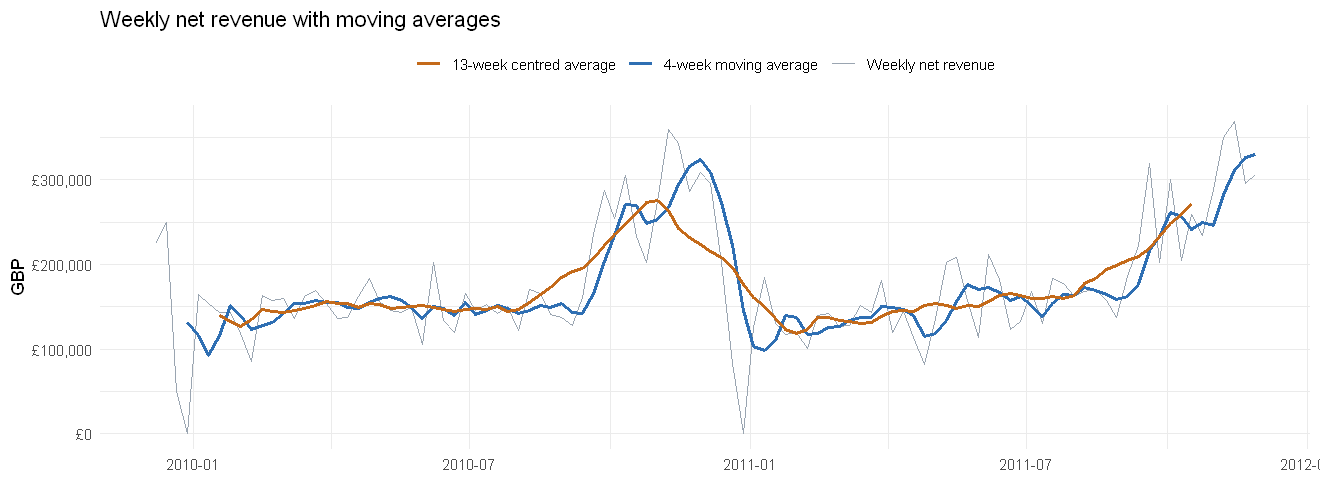

In [4]:
weekly <- weekly |>
  mutate(ma4  = as.numeric(stats::filter(net_revenue, rep(1 / 4, 4),  sides = 1)),
         ma13 = as.numeric(stats::filter(net_revenue, rep(1 / 13, 13), sides = 2)))
p <- ggplot(weekly, aes(period)) +
  geom_line(aes(y = net_revenue, colour = "Weekly net revenue"), linewidth = 0.4) +
  geom_line(aes(y = ma4,  colour = "4-week moving average"), linewidth = 1, na.rm = TRUE) +
  geom_line(aes(y = ma13, colour = "13-week centred average"), linewidth = 1, na.rm = TRUE) +
  scale_colour_manual(values = c("Weekly net revenue" = "#9AA5B1",
                                 "4-week moving average" = "#2F6FB3",
                                 "13-week centred average" = "#C46A1A"), name = NULL) +
  scale_y_continuous(labels = label_dollar(prefix = "£")) +
  labs(title = "Weekly net revenue with moving averages", x = NULL, y = "GBP") +
  theme_minimal(base_size = 11) + theme(legend.position = "top")
ggsave(file.path(fig, "bq1_weekly_revenue_r.png"), p, width = 11, height = 4, dpi = 150)
p

## BQ1: Trend regression with HAC (Newey-West) standard errors
`df = Inf` reports z-tests, matching Python's statsmodels.

In [5]:
# t counts every calendar week; weeks with no sales are then left out of the log model
trend_df <- weekly |>
  mutate(t = row_number() - 1,
         q4 = as.integer(month(period) %in% c(10, 11, 12))) |>
  filter(net_revenue > 0) |>
  mutate(log_rev = log(net_revenue))
cat("Weeks used in the log regression:", nrow(trend_df), "\n")

m1 <- lm(log_rev ~ t, data = trend_df)
hac1 <- coeftest(m1, vcov = NeweyWest(m1, lag = 4, prewhite = FALSE), df = Inf)
print(hac1)
b <- coef(m1)["t"]
cat(sprintf("Trend: %+.2f%% per week = %+.1f%% per year\n", 100 * (exp(b) - 1), 100 * (exp(52 * b) - 1)))
cat(sprintf("p-value, naive OLS: %.4f   HAC robust: %.4f\n",
            summary(m1)$coefficients["t", 4], hac1["t", 4]))

m2 <- lm(log_rev ~ t + q4, data = trend_df)
hac2 <- coeftest(m2, vcov = NeweyWest(m2, lag = 4, prewhite = FALSE), df = Inf)
cat(sprintf("Trend with Q4 control: %+.1f%% per year (p = %.4f);  Q4 uplift: %+.1f%%\n",
            100 * (exp(52 * coef(m2)["t"]) - 1), hac2["t", 4], 100 * (exp(coef(m2)["q4"]) - 1)))

Weeks used in the log regression: 102 

z test of coefficients:

              Estimate Std. Error  z value             Pr(>|z|)    
(Intercept) 11.8422077  0.0730070 162.2064 < 0.0000000000000002 ***
t            0.0037461  0.0014933   2.5085              0.01212 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Trend: +0.38% per week = +21.5% per year
p-value, naive OLS: 0.0013   HAC robust: 0.0121
Trend with Q4 control: +14.6% per year (p = 0.0126);  Q4 uplift: +56.2%


## BQ1: Trend with month-of-year controls and moving annual total
A dummy for every month removes the seasonal confounding; the moving annual total covers a full year of seasons in every point.

Trend with month-of-year controls: +2.1% per year (p = 0.520)
Moving annual total: £9,078,831 (2010-11-29) -> £9,283,162 (2011-11-28), +2.3%


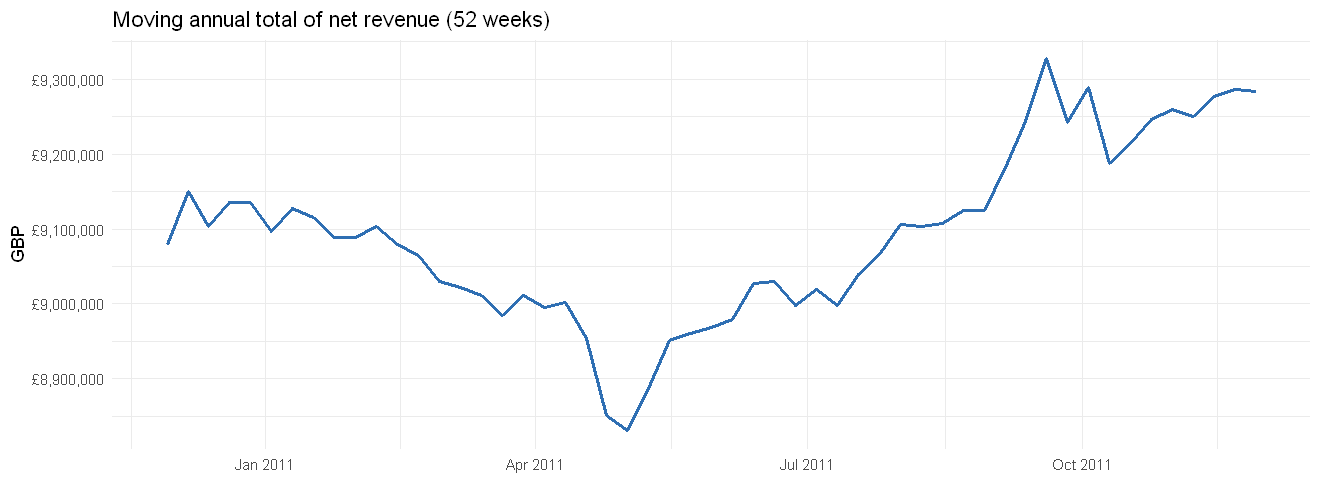

In [6]:
trend_fe <- weekly |>
  mutate(t = row_number() - 1, moy = factor(month(period))) |>
  filter(net_revenue > 0) |>
  mutate(log_rev = log(net_revenue))
fe <- lm(log_rev ~ t + moy, data = trend_fe)
hac_fe <- coeftest(fe, vcov = NeweyWest(fe, lag = 4, prewhite = FALSE), df = Inf)
cat(sprintf("Trend with month-of-year controls: %+.1f%% per year (p = %.3f)\n",
            100 * (exp(52 * coef(fe)["t"]) - 1), hac_fe["t", 4]))

mat <- weekly |>
  mutate(mat = as.numeric(stats::filter(net_revenue, rep(1, 52), sides = 1))) |>
  filter(!is.na(mat))
cat(sprintf("Moving annual total: £%s (%s) -> £%s (%s), %+.1f%%\n",
            comma(first(mat$mat)), first(mat$period), comma(last(mat$mat)), last(mat$period),
            100 * (last(mat$mat) / first(mat$mat) - 1)))

p_mat <- ggplot(mat, aes(period, mat)) +
  geom_line(colour = "#2F6FB3", linewidth = 1) +
  scale_y_continuous(labels = label_dollar(prefix = "£")) +
  labs(title = "Moving annual total of net revenue (52 weeks)", x = NULL, y = "GBP") +
  theme_minimal(base_size = 11)
ggsave(file.path(fig, "bq1_moving_annual_total_r.png"), p_mat, width = 11, height = 4, dpi = 150)
p_mat

## BQ2: Decomposition
R's `stl()` needs more than two full yearly cycles; with exactly 104 weeks the classical `decompose()` is used. It loses 26 weeks of trend at each end, so treat it as indicative.

Weeks: 104   full yearly cycles: 2 
Seasonal index (deviation from trend, GBP) at trough and peak:
[1] -171019  191359


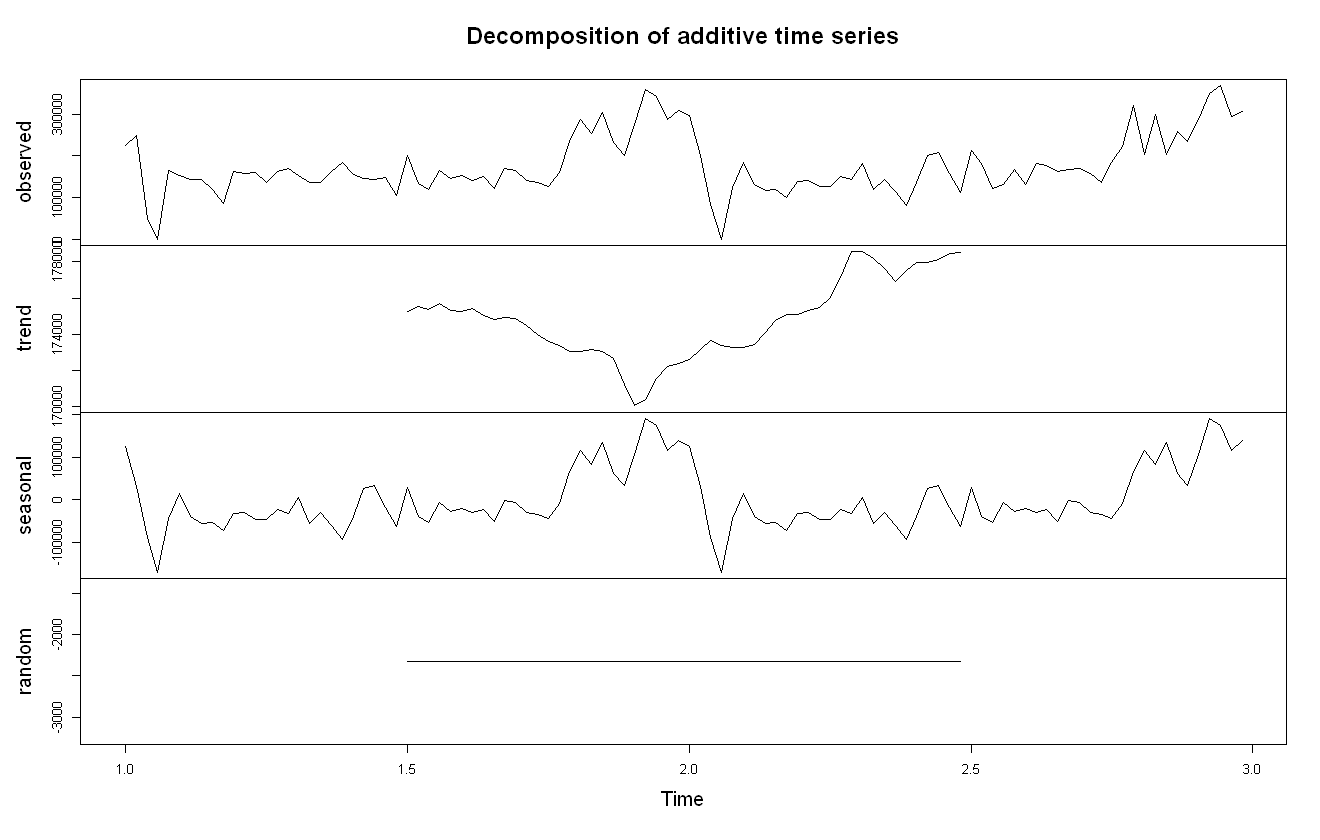

In [7]:
w_ts <- ts(weekly$net_revenue, frequency = 52)
cat("Weeks:", length(w_ts), "  full yearly cycles:", length(w_ts) / 52, "\n")
dec <- decompose(w_ts, type = "additive")
options(repr.plot.height = 7)
plot(dec)
png(file.path(fig, "bq2_decomposition_r.png"), width = 1650, height = 1050, res = 150)
plot(dec); invisible(dev.off())
options(repr.plot.height = 4)
cat("Seasonal index (deviation from trend, GBP) at trough and peak:\n")
print(round(range(dec$figure)))

## BQ2: Autocorrelation

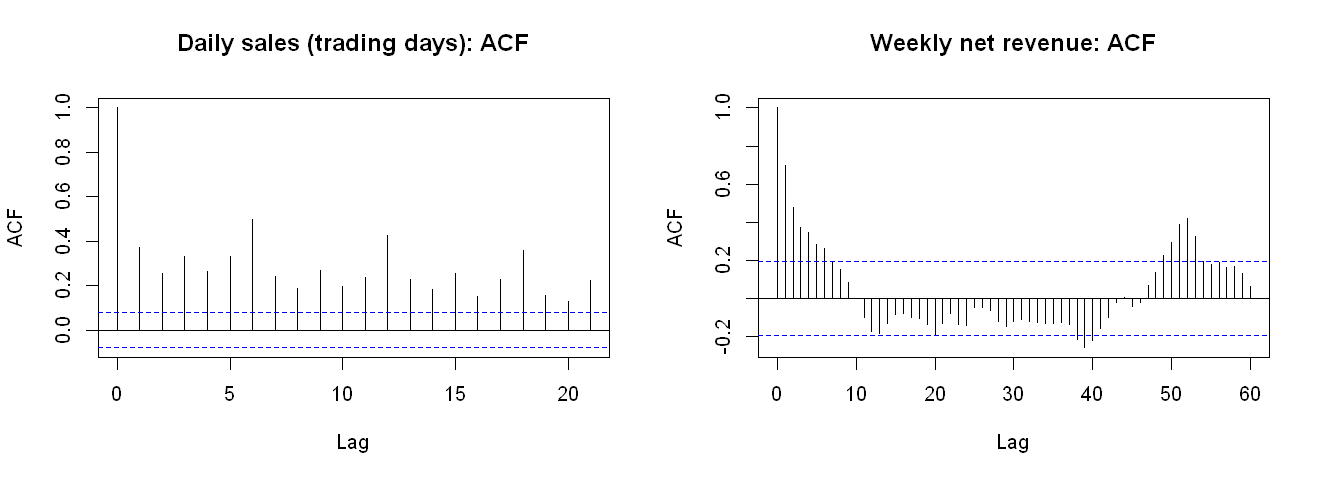

In [8]:
daily <- prod |> filter(date < as.Date("2011-12-01")) |>
  group_by(date) |> summarise(revenue = sum(revenue)) |> arrange(date)
par(mfrow = c(1, 2))
acf(daily$revenue, lag.max = 21, main = "Daily sales (trading days): ACF")
acf(weekly$net_revenue, lag.max = 60, main = "Weekly net revenue: ACF")
par(mfrow = c(1, 1))

## BQ2: Month, weekday and hour patterns
Saturday is excluded: its only sales are a one-off opening on 5 Dec 2009.

In [9]:
q4_share <- monthly |> summarise(s = sum(net_revenue[month(period) %in% 10:12]) / sum(net_revenue))
cat(sprintf("Q4 (Oct-Dec) share of net revenue: %.1f%%\n", 100 * q4_share$s))

by_weekday <- prod |>
  filter(weekday != "Saturday") |>
  group_by(weekday) |>
  summarise(per_trading_day = sum(revenue) / n_distinct(date)) |>
  mutate(weekday = factor(weekday, levels = c("Monday", "Tuesday", "Wednesday",
                                              "Thursday", "Friday", "Sunday"))) |>
  arrange(weekday)
print(by_weekday)

by_hour <- prod |> group_by(hour) |> summarise(share = sum(revenue)) |> mutate(share = share / sum(share))
cat("Busiest hours (top 3):", head(by_hour$hour[order(-by_hour$share)], 3), "\n")

Q4 (Oct-Dec) share of net revenue: 35.1%


# A tibble: 6 × 2
  weekday   per_trading_day
  <fct>               <dbl>
1 Monday             36347.
2 Tuesday            37309.
3 Wednesday          32455.
4 Thursday           38934.
5 Friday             31986.
6 Sunday             18032.
Busiest hours (top 3): 12 10 13 
